<a href="https://colab.research.google.com/github/DEESHA-AFK/MACHINE-LEARNING-FUNDAMENTALS/blob/main/T076_ML_PRAC_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AIM: 1. KNN for botanical species identification
Implement KNN (Euclidean distance, experiment with K=3,5,7) on the Iris
dataset to classify flower species (real-world agriculture/plant taxonomy).
Compute distance manually for first 5 test samples.

Load Dataset & Before KNN Graph

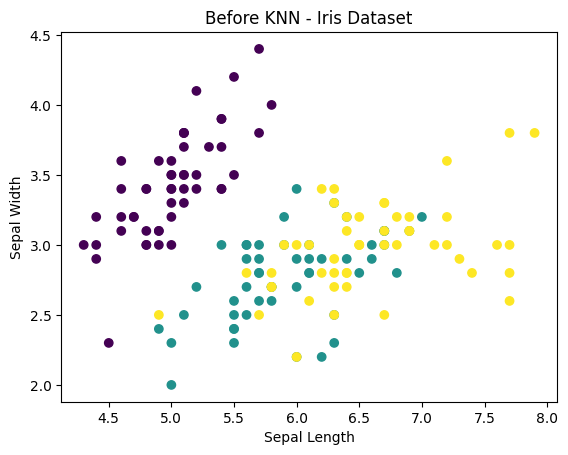

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

plt.scatter(X[:,0], X[:,1], c=y)
plt.title("Before KNN - Iris Dataset")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Manual Euclidean Distance & KNN

In [ ]:
for i in range(5):
    distances = []
    for j in range(len(X_train)):
        d = np.sqrt(np.sum((X_test[i]-X_train[j])**2))
        distances.append(d)
    print("Sample", i+1, "Distances:", np.round(sorted(distances)[:5], 2))

accuracies = []

for k in [3, 5, 7]:
    model = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)*100
    accuracies.append(acc)
    print("K =", k, "Accuracy =", round(acc, 2), "%")

Sample 1 Distances: [0.22 0.3  0.44 0.51 0.51]
Sample 2 Distances: [0.33 0.39 0.47 0.51 0.52]
Sample 3 Distances: [0.41 0.55 0.89 0.93 0.96]
Sample 4 Distances: [0.2  0.24 0.33 0.35 0.41]
Sample 5 Distances: [0.32 0.35 0.35 0.37 0.42]
K = 3 Accuracy = 100.0 %
K = 5 Accuracy = 100.0 %
K = 7 Accuracy = 96.67 %


After KNN Graph & Accuracy Comparison

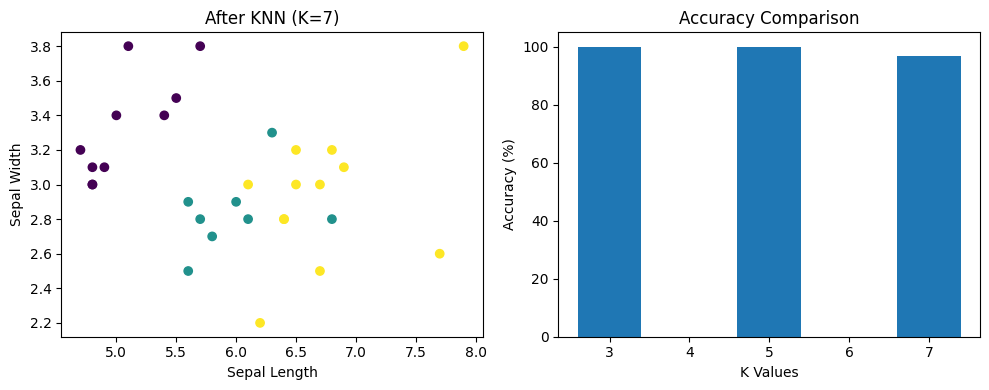

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.scatter(X_test[:,0], X_test[:,1], c=pred)
plt.title("After KNN (K=7)")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.subplot(1,2,2)
plt.bar([3,5,7], accuracies)
plt.title("Accuracy Comparison")
plt.xlabel("K Values")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()